# Part A

## 1. Loading the data into pandas dataframes

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ratings_df = pd.read_csv('data/ratings.csv')
movies_df = pd.read_csv('data/movies.csv')


## 2. Report

In [2]:
unique_users = ratings_df['userId'].nunique()
unique_movies = ratings_df['movieId'].nunique()
num_ratings = ratings_df.shape[0]
sparsity = 1 - (num_ratings / (unique_users * unique_movies))

print("Number of unique users:", unique_users)
print("Number of unique movies:", unique_movies)
print("Number of ratings:", num_ratings)
print(f"Sparsity of the ratings matrix: {sparsity:.3%}")

Number of unique users: 610
Number of unique movies: 9724
Number of ratings: 100836
Sparsity of the ratings matrix: 98.300%


## 3. Building the user-item matrix

In [3]:
matrix = ratings_df.pivot_table(index='userId', columns='movieId', values='rating')

## 4. Plotting

### 4.1 Distribution of ratings

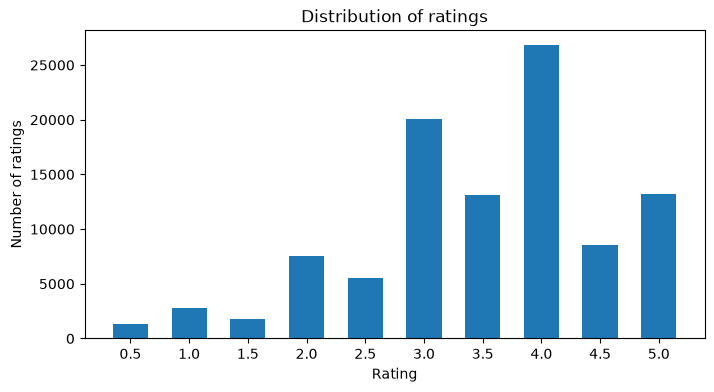

In [4]:
rating_counts = ratings_df["rating"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(rating_counts.index, rating_counts.values, width=0.3)
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.title("Distribution of ratings")
plt.xticks(rating_counts.index)
plt.show()

### 4.2 Distribution of ratings per user

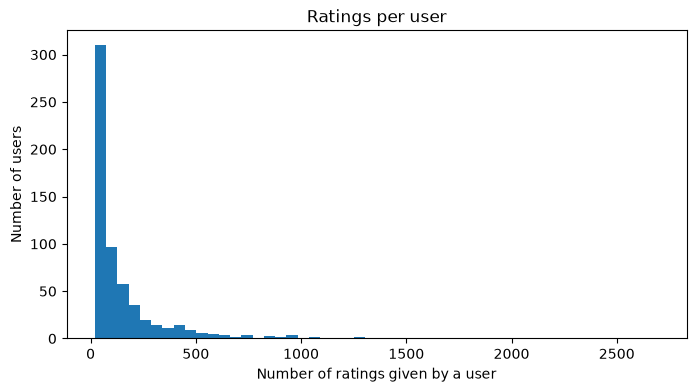

In [5]:
ratings_per_user = ratings_df.groupby('userId').size()

plt.figure(figsize=(8, 4))
plt.hist(ratings_per_user, bins=50)
plt.xlabel("Number of ratings given by a user")
plt.ylabel("Number of users")
plt.title("Ratings per user")
plt.show()

### Notes:-

1) In the distributions of ratings: 4.0 and 3.0 are the most common ratings, And that the whole numbers always beat the half-steps, People usually approximates to the whole number than using the halfs.

2) In the distribution of ratings per user: most users rated only a small number of movies, while a few users rated over 1000 movies, and one rated about 2700 movies. Since each user covers only a tiny fraction of the catalog, two users often share very few co-rated items.

# temp Part B

In [6]:
# temporary 
def get_co_rated(matrix, a, b, axis):
    if axis == "index":
        va, vb = matrix.loc[a].values, matrix.loc[b].values
    else:
        va, vb = matrix[a].values, matrix[b].values
    mask = ~np.isnan(va) & ~np.isnan(vb)
    return va[mask], vb[mask]

def cosine_similarity(vec1, vec2):
    return np.dot(vec1, vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))

def pearson_similarity(vec1, vec2):
    a = vec1 - vec1.mean()
    b = vec2 - vec2.mean()
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    if denom == 0:
        return np.nan
    return np.dot(a, b) / denom


# Part C

## 9. Find k nearest users

In [7]:
def find_k_nearest_users(matrix,target_user,k,similarity_fn):
    scores = []
    for user in matrix.index:
        if user != target_user:
            vec1, vec2 = get_co_rated(matrix, target_user, user, axis="index")
            if (len(vec1) < 2):
                continue
            score = similarity_fn(vec1, vec2)
            if np.isnan(score):
                continue
            scores.append((user, score))

    return sorted(scores, key=lambda t: t[1], reverse=True)[:k]



## 10. Predict rating user based

In [8]:
def predict_rating_user_based(matrix,target_user,target_item,k,similarity_fn):
    if target_item not in matrix.columns:
        return None
    if target_user not in matrix.index:
        return None
    
    neighbors = find_k_nearest_users(matrix, target_user, k, similarity_fn)
    numerator = 0
    denominator = 0
    for user, score in neighbors:
        rating = matrix.loc[user, target_item]
        if np.isnan(rating):
            continue
        numerator += score * rating
        denominator += abs(score)
    if denominator == 0:
        return None
    return numerator / denominator


# Part D

## 11.1 Find k nearest items

In [9]:
def find_k_nearest_items(matrix, target_item, k, similarity_fn):
    scores = []
    for item in matrix.columns:
        if item != target_item:
            vec1, vec2 = get_co_rated(matrix, target_item, item, axis="columns")
            if (len(vec1) < 2):
                continue
            score = similarity_fn(vec1, vec2)
            if np.isnan(score):
                continue
            scores.append((item, score))
            
    return sorted(scores, key=lambda t: t[1], reverse=True)[:k]



## 11.2 Predict rating item based

In [10]:
def predict_rating_item_based(matrix,target_user,target_item,k,similarity_fn):
    if target_item not in matrix.columns:
        return None
    if target_user not in matrix.index:
        return None
    
    neighbors = find_k_nearest_items(matrix, target_item, k, similarity_fn)
    numerator = 0
    denominator = 0
    for item, score in neighbors:
        rating = matrix.loc[target_user, item]
        if np.isnan(rating):
            continue
        numerator += score * rating
        denominator += abs(score)
    if denominator == 0:
        return None
    return numerator / denominator


## 12. Explanation:-

We reused the same logic from part C, checking the same structure of the neighbor search (loop, skip himself, skip if fewer than 2 co-rated, applying similarity_fn) and using the same average formula.

We changed only that the loop runs over columns not rows (axis = "columns" instead axis = "index") and the rating lookups flips from (matrix.loc[neighbor, target_item]) to (matrix.loc[target_user, neighbor_item]).

# Part F

## 16. - Which metric performed best? (fill after the real grid is run)
**TODO: copy numbers from your own table.** Template (replace `<...>`, delete what doesn't hold):

Best configuration in my table: `<method>` with `<metric>` and k = `<k>`, RMSE = `<..>`, MAE = `<..>`, `<..>`% of test ratings had no prediction.
Worst: `<...>`.

*Does it match Section 3.2?* Section 3.2 predicts that Pearson (mean-centering) should beat cosine, and cosine should beat Euclidean, because Euclidean confuses "different baseline" with "different taste". `<Yes / no>`: in my results, `<metric A>` beat `<metric B>` by `<difference>` RMSE.

*Where it may disagree (check each against your table, keep only what you observe):*
* With co-rated-only data, any two users who share just 2 items have Pearson = +1 or -1 exactly, so Pearson is noisy for low-overlap pairs and can pick bad neighbours at small k.
* Cosine on all-positive ratings is always high (most values 0.9+), so it barely separates good neighbours from bad ones; it only measures angle, not how many items overlap.
* Euclidean similarity 1/(1+d) rewards pairs with *few* co-rated items (a small sum gives a small d), so it can rank users with tiny overlap as very similar, which can hurt it. But because raw predictions are weighted averages of raw ratings (no mean-centering), the bias issue is smaller than the theory suggests, so Euclidean can still be competitive.
* Larger k usually helps until noisy neighbours are included; `<describe what your k trend shows>`.
* User-based vs item-based: `<which was better and by how much; which had a larger frac_none>`.


## 17. Example

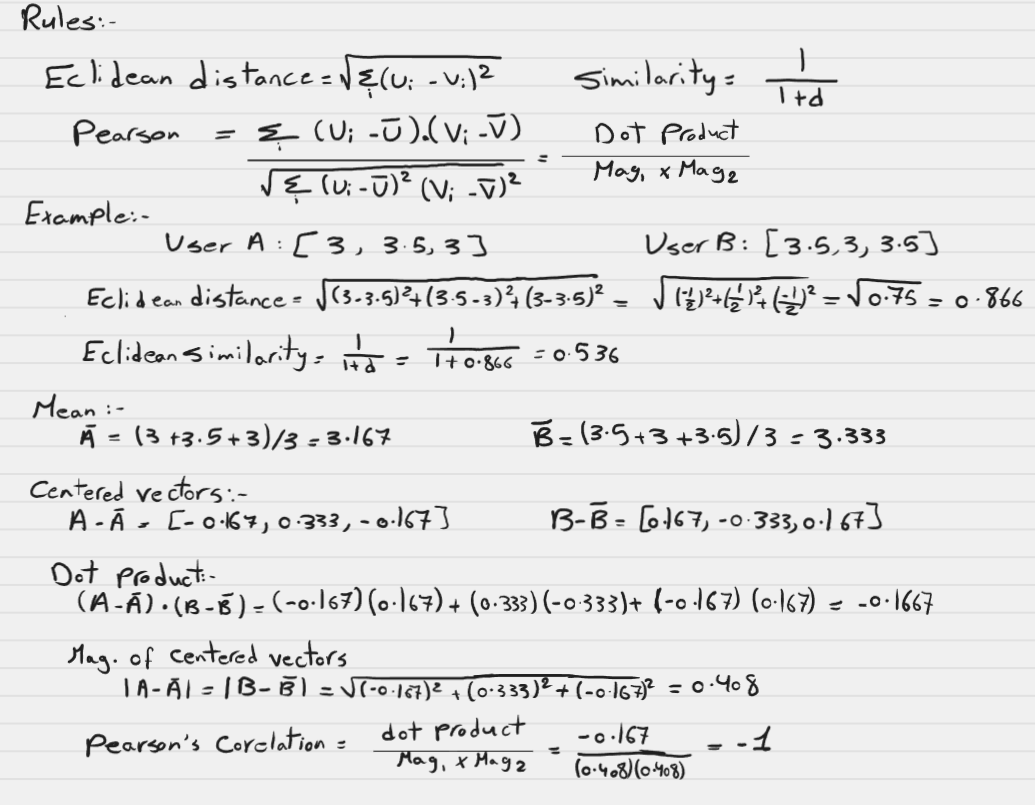

According to the calculations of the example.. Eclidean Similarity shows that the two users are close to be similar (0.536). While Pearson's Corelation shows that the two users are completly opposite (-1).
They disagree because Eclidean similarity depends on gaps only, while pearson compares the two users with their own averages.

## 18. Comparison between user-based CF and item-based CF

The user-based collaborative filtering is nearly impossible to be up to date in large systems, because as in the example, each target user is compared with 200 million other users, so if we needed to compare all users its (200M x 200M) = 2x(10^16) comparisons, this is not efficient at all and very expensive.

On the other hand, the item-based collaborative filtering is very convinient in comparison with the user-based, as in the example, with only 20,000 products, if we wanted to compare each target item with all the other items we will get (20K x 20K) = 2x(10^8) comparisons only, this is much cheaper and efficient to stay up to date. 

# Bonus

## Mean-centring

In [11]:
def predict_rating_user_based_centered(matrix, target_user, target_item, k, similarity_fn):
    if target_item not in matrix.columns or target_user not in matrix.index:
        return None
    neighbors = find_k_nearest_users(matrix, target_user, k, similarity_fn)
    target_mean = matrix.loc[target_user].mean()
    numerator = 0
    denominator = 0
    for user, score in neighbors:
        rating = matrix.loc[user, target_item]
        if np.isnan(rating):
            continue
        neighbor_mean = matrix.loc[user].mean()
        numerator += score * (rating - neighbor_mean)
        denominator += abs(score)
    if denominator == 0:
        return None
    return target_mean + (numerator / denominator)


### Comparing RMSE with plain Pearson-weighted prediction

In [12]:
sample = ratings_df.sample(200, random_state=42)

errors_plain, errors_centered = [], []
none_plain = none_centered = 0

for _, row in sample.iterrows():
    u, i, true = int(row["userId"]), int(row["movieId"]), row["rating"]
    matrix.loc[u, i] = np.nan                        # hide the true rating
    p1 = predict_rating_user_based(matrix, u, i, 20, pearson_similarity)
    p2 = predict_rating_user_based_centered(matrix, u, i, 20, pearson_similarity)
    matrix.loc[u, i] = true                          # restore it

    if p1 is None:
        none_plain += 1
    else:
        errors_plain.append(p1 - true)

    if p2 is None:
        none_centered += 1
    else:
        errors_centered.append(p2 - true)

rmse_plain = np.sqrt(np.mean(np.square(errors_plain)))
rmse_centered = np.sqrt(np.mean(np.square(errors_centered)))

print("Plain    RMSE:", rmse_plain, "  None:", none_plain)
print("Centered RMSE:", rmse_centered, "  None:", none_centered)

Plain    RMSE: 1.0207784016599941   None: 151
Centered RMSE: 1.0972196005315409   None: 151


The two predictors almost share everything: they share the same neighbors and same weights because they call the function (find_k_nearest_users), pearson already mean-centers inside the similarity.

## Top-10 recommendations for one user
Predicted ratings for all items the user has not rated, using the user-based method, then a manual genre check.